# P3: MDPs and Bandit Algorithms

**Instructions for submission are the same as they have been.**

## P3.1 MDPs: Evaluating Policies

In class, we discussed two different ways of evaluating a policy: First-visit MC prediction and a linear-algebra-based procedure.

I'm giving you a random adjacency graph for you to play around with. The agent's goal is to maximize its reward (which happens when it reaches the node in the "middle" of the graph). There's a catch: actions are somewhat stochastic. Every time the agent executes an action, there is a random chance it will end up in any of the states reachable from its current state. I am providing you with a couple *policies*: functions that take in a state and return the action the agent should take. **Policy 1** is a random policy: in each state it picks one of the available moves at random (chosen once, then fixed). **Policy 2** greedily heads for the goal: in each state it moves to the neighbor whose index is closest to the goal's.

This is the environment that you will be using for most of your assignment, so you might want to read through it to make sure you understand what's going on. A few things to note:

$P(s' | s, a) = $ `world.get_transition_probs(state, action)`

$R(s) = $ `world.rewards`

Also, if you have a value function $V(s)$, this means that $\sum_{s' \in S} P(s' | s, a) V(s')$ = `np.dot(world.get_transition_probs(state, action), values)`. I'm sure this will help you in your answers below!

Note that in your implementations, sometimes you want to get the argmax or argmin of some list: you want to find the action that maximizes or minimizes some value. Here's an example: if you want to find the action that minimizes the value of `something`, you can use the following code:
```python
actions = env.get_actions_for_state(state)
action_index = np.argmin(something[actions])
minimizing_action = actions[action_index]
```
Your list of actions acts as a list of indices for the `something` vector, so `something[actions]` gives you the values of `something` for those actions. `np.argmin` gives you the index that minimizes `something[actions]`. With that index, you can plug it back into the list of actions to get the action that would have minimized `something`. I expect you will find this useful for a few aspects of your implementation.

In [6]:
# Graph definition and plotting

import matplotlib.pyplot as plt
import numpy as np
import random


def get_random_adjacency(band_size, num_nodes, edge_rate=1.0, seed=695):
    random.seed(seed)
    mat = np.zeros((num_nodes, num_nodes))
    for ii in range(num_nodes):
        mat[ii, ii] = 1.0
        for jj in range(ii + 1, min(ii + band_size, num_nodes)):
            val = 1.0 * (random.random() < edge_rate)
            mat[ii, jj] = val
            mat[jj, ii] = val
    return mat


def plot_adjacency_mat(mat):
    plt.figure(dpi=150)
    plt.xticks([], [])
    plt.yticks([], [])
    plt.imshow(mat, interpolation="none")


class AdjacencyWorld(object):
    def __init__(
        self, num_nodes, band_size=10, edge_rate=0.5, random_move_chance=0.5, seed=695
    ):
        self.mat = get_random_adjacency(
            band_size=band_size, num_nodes=num_nodes, edge_rate=edge_rate, seed=seed
        )
        self.states = list(range(num_nodes))
        self.rewards = -1 * np.ones((num_nodes))
        self.goal = num_nodes // 2
        self.rewards[self.goal] = 10
        self.random_move_chance = random_move_chance

    def get_actions_for_state(self, state):
        """Get the available 'moves' from the current state.
        return: list of indices connected to 'state'."""
        return np.where(self.mat[state])[0].tolist()

    def get_transition_probs(self, state, action):
        """Get a list of the transition probabilities for a state and action."""
        actions = self.get_actions_for_state(state)
        num_actions = len(actions)
        prob_vec = np.zeros_like(self.rewards)
        for rand_action in actions:
            prob_vec[rand_action] = self.random_move_chance / num_actions

        prob_vec[action] += 1 - self.random_move_chance
        return prob_vec

    def get_random_state(self):
        return random.choice(self.states)

    def execute_action(self, state, action):
        assert action in self.get_actions_for_state(state)
        probs = self.get_transition_probs(state, action)
        new_state = np.random.choice(self.states, p=probs)
        return self.rewards[new_state], new_state

### P3.1.1 First-Visit MC Policy Evaluation

**TASK** Complete the `evaluate_policy_first_visit_mc` function below using the First Visit MC prediction algorithm we discussed in class. 

I have provided you with significant starter code for this purpose. At each step during the MC evaluation, I record the current state and action, the reward returned after executing the action, and the states that have been visited so far (needed to evaluate whether it was a *first visit*). In the final loop, which you should complete, we iterate through that list backwards, as it is done in the algorithm pseudocode from class. It might also help you to know that I have stored the returns as a python dictionary; when you want to add a new 'return', you should use something that looks like `returns[state] += [something]`. Once you have populated the returns, computing the values can be done by looping through `state, returns in returns.items()`; feel free to use a value of 0 if `len(returns) == 0`.

When completed, if implemented correctly, for a "random move chance" of 0.2, the average value of policy 1 should be roughly -50 and the average return value of policy 2 should be roughly 26 (plus or minus five or so).

**CODE** Include your completed implementation in your writeup.

**RESULTS** Include the computed output average values for each of the provided policies.

**PLOTS** Include the generated plot of the computed value for each policy (for a random move chance of 0.5) in your writeup.

**QUESTION** (1-2 sentences) How do the costs of each policy compare as the random move chance becomes 1.0? Why?

In [7]:
# STARTER CODE: First Visit MC Policy Evaluation


def evaluate_policy_first_visit_mc(
    world, policy, num_iterations=1000, gamma=0.98, num_steps=400, seed=695
):
    """Returns a list such that value[state] is the value of that state."""
    # Perform a bunch of rollouts
    random.seed(seed)
    np.random.seed(seed)
    returns = {s: [] for s in world.states}

    for _ in range(num_iterations):
        # Rollout
        state = world.get_random_state()
        steps = []
        states_so_far = set()
        for _ in range(2 * num_steps):
            action = policy[state]
            reward, new_state = world.execute_action(state, action)
            steps.append((state, action, reward, states_so_far.copy()))
            states_so_far.add(state)
            state = new_state

        G = 0
        for s, a, r, states_so_far in reversed(steps[:num_steps]):
            # raise NotImplementedError()
            G = gamma * G + r
            if s not in states_so_far:
                returns[s] += [G]

    # Return the values
    # raise NotImplementedError()
    values = np.zeros(len(world.states))
    for state, rets in returns.items():
        values[state] = np.mean(rets) if len(rets) > 0 else 0
    return values

== Policy 1 ==
 Chance:  0.0 | Average Value: -49.98, std. dev: 0.00
 Chance:  0.2 | Average Value: -46.07, std. dev: 1.79
 Chance:  0.5 | Average Value: -45.60, std. dev: 1.95
 Chance:  0.8 | Average Value: -44.98, std. dev: 2.23
 Chance:  1.0 | Average Value: -43.93, std. dev: 2.68
== Policy 2 ==
 Chance:  0.0 | Average Value: 15.60, std. dev: 170.03
 Chance:  0.2 | Average Value: 27.45, std. dev: 89.26
 Chance:  0.5 | Average Value: -12.89, std. dev: 23.48
 Chance:  0.8 | Average Value: -35.27, std. dev: 6.69
 Chance:  1.0 | Average Value: -43.93, std. dev: 2.68


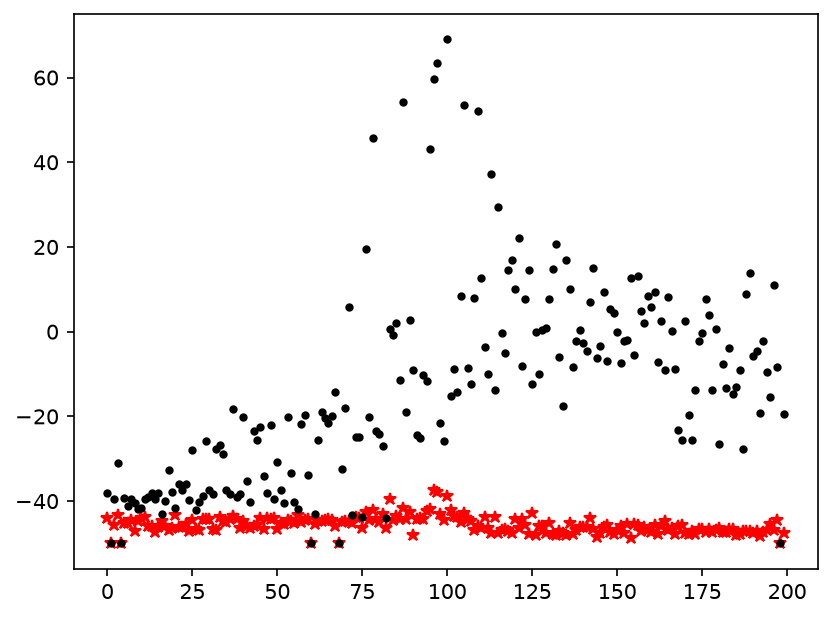

In [8]:
# Plotting and evaluation code
world = AdjacencyWorld(
    200, band_size=20, edge_rate=0.1, random_move_chance=0.0, seed=695
)


# Policy 1
policy_1 = [random.choice(world.get_actions_for_state(state)) for state in world.states]

# Policy 2
policy_2 = [0] * len(world.states)
for state in world.states:
    actions = np.array(world.get_actions_for_state(state))
    action_ind = np.argmin(np.abs(actions - world.goal))
    policy_2[state] = actions[action_ind]


def evaluate_policy_multiple(world, policy):
    for rmc in [0.0, 0.2, 0.5, 0.8, 1.0]:
        world.random_move_chance = rmc
        values = evaluate_policy_first_visit_mc(world, policy)
        print(
            f" Chance: {rmc:4.1f} | Average Value: {np.mean(values):0.2f}, std. dev: {np.std(values):0.2f}"
        )


plt.figure(dpi=150)
world.random_move_chance = 0.5
plt.plot(evaluate_policy_first_visit_mc(world, policy_1), "r*")
plt.plot(evaluate_policy_first_visit_mc(world, policy_2), "k.")

print("== Policy 1 ==")
evaluate_policy_multiple(world, policy_1)

print("== Policy 2 ==")
evaluate_policy_multiple(world, policy_2)

None

### P3.1.2 Linear Algebra Evaluation

As we discussed in class, there is a more direct (non-sampling-based) way to tackle this problem: linear algebra. While the strategy doesn't scale well to large problems, ours is small enough that it won't matter much. This method aims to solve the following linear system:

$$ V(s) = R_s + \gamma \sum_{s'} P(s' | s, a)V(s') $$

In matrix form, we can write this as follows:

$$ V = R + \gamma P V $$

Rearranging, we find:

$$ (\mathbb{I} - \gamma P) V = R $$

where $\mathbb{I}$ is the identity matrix (implemented in numpy as `np.eye(N)`, where N is the side length). Numpy can be used to solve for a linear system like this. If $Ax = b$, then `x = np.linalg.solve(A, b)`. It is up to you to figure out how to build the $P$ matrix using `world.get_transition_probs(state, action)` (where `action = policy[state]` by definition of the policy).

Your results should be pretty close to the previous implementation, though the computation will no doubt be significantly faster.

**TASK** Complete the `evaluate_policy` function below.

**CODE** Include the completed `evaluate_policy` function in your writeup.

**RESULTS** Include the computed output average values for each of the provided policies.

**PLOTS** Include the generated plot of the computed value for each policy (for a random move chance of 0.5) in your writeup.

**QUESTION** (1-2 sentences) How do the costs of each policy compare as the random move chance becomes 1.0? Why?

In [9]:
def evaluate_policy(env, policy, gamma=0.98):
    """Returns a list of values[state]."""
    # raise NotImplementedError()
    P = np.array([env.get_transition_probs(s, policy[s]) for s in env.states])
    return np.linalg.solve(np.eye(len(env.states)) - gamma * P, env.rewards)

== Policy 1 ==
 Chance:  0.0 | Average Value: -49.94, std. dev: 0.78
 Chance:  0.2 | Average Value: -49.67, std. dev: 1.26
 Chance:  0.5 | Average Value: -49.24, std. dev: 1.63
 Chance:  0.8 | Average Value: -48.46, std. dev: 2.15
 Chance:  1.0 | Average Value: -47.56, std. dev: 2.77
== Policy 2 ==
 Chance:  0.0 | Average Value: 14.35, std. dev: 166.85
 Chance:  0.2 | Average Value: 22.62, std. dev: 79.89
 Chance:  0.5 | Average Value: -13.93, std. dev: 23.28
 Chance:  0.8 | Average Value: -37.61, std. dev: 7.02
 Chance:  1.0 | Average Value: -47.56, std. dev: 2.77


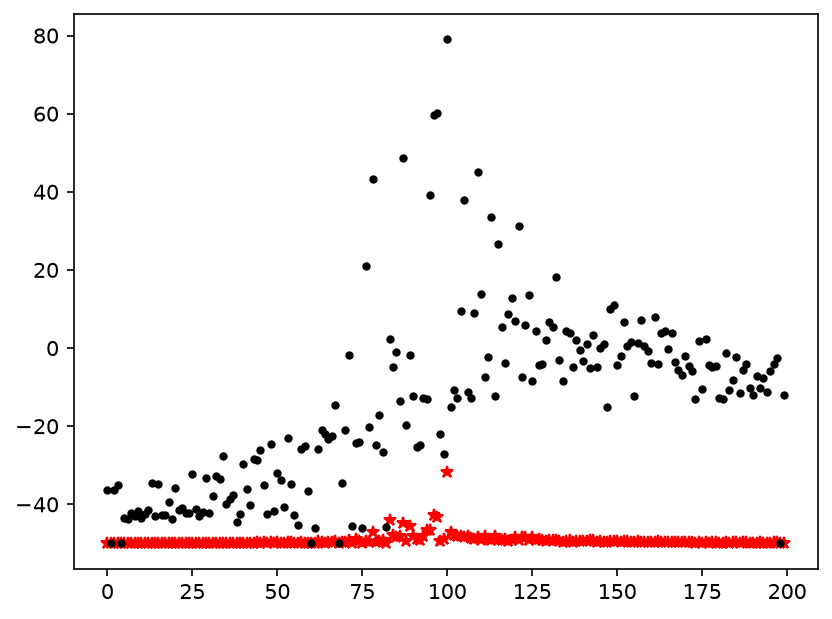

In [10]:
def evaluate_policy_multiple(world, policy):
    for rmc in [0.0, 0.2, 0.5, 0.8, 1.0]:
        world.random_move_chance = rmc
        values = evaluate_policy(world, policy)
        print(
            f" Chance: {rmc:4.1f} | Average Value: {np.mean(values):0.2f}, std. dev: {np.std(values):0.2f}"
        )


plt.figure(dpi=150)
world.random_move_chance = 0.5
plt.plot(evaluate_policy(world, policy_1), "r*")
plt.plot(evaluate_policy(world, policy_2), "k.")

print("== Policy 1 ==")
evaluate_policy_multiple(world, policy_1)

print("== Policy 2 ==")
evaluate_policy_multiple(world, policy_2)

None

## P3.2 Value Iteration

In class, we looked at *Value Iteration* as a technique to compute the *optimal policy*. Here, you will implement two functions relevant to this problem: value iteration itself, and a separate function that is used to determine the optimal policy from the computed values and the world model. First, you will implement value iteration.

**TASK** Implement the `value_iteration` function below using information from the in-class slides for how to iteratively update the value function. Key to this is that you are trying to find the action which will maximize the future expected reward. For this purpose, you will need both `world.get_actions_for_state(state)` and `world.get_transition_probs(state, action)`.

**CODE** Include your implementation of `value_iteration` in your writeup.

Next you will need to compute the policy from the values you computed above. For our scenario, to compute the policy from values, you should use the following formula.

$$ \pi^*(s) = \arg\max_a \sum_{s' \in S} P(s' | s, a) V^*(s') $$

**TASK** Implement the `compute_policy_from_values` function.

**CODE** Include your implementation of `compute_policy_from_values` in your writeup.

**RESULTS & PLOTS** Finally, run the code below and include the plots and results.

**QUESTION** (2-3 sentences) There are a few states for which the value is very low for all three values of random move chance. Why is this the case?

In [11]:
# Starter Code


def value_iteration(world, num_iterations, gamma=0.98):
    # values is a vector containing the value for each state.
    values = world.rewards.copy()
    # values_over_iterations is a vector of the values at each iteration (for visualization)
    values_over_iterations = [values.copy()]

    for _ in range(num_iterations):
        # Perform one step of value iteration
        # raise NotImplementedError()
        new_values = np.zeros_like(values)
        for s in world.states:
            best = max(np.dot(world.get_transition_probs(s, a), values)
                for a in world.get_actions_for_state(s))
            new_values[s] = world.rewards[s] + gamma * best
        values = new_values
        values_over_iterations.append(values.copy())

        # Store the values in 'values_over_iterations' (for visualization)
        values_over_iterations.append(values.copy())

    # Return values_over_iterations; values_over_iterations[-1] are the final values.
    return values_over_iterations


def compute_policy_from_values(world, values):
    """policy is a mapping from states -> actions.
    Here, it's just a vector: action = policy[state]"""
    # Initialize the policy vector
    policy = np.zeros_like(world.states)

    # Compute the policy for every state
    # raise NotImplementedError()
    for s in world.states:
        actions = world.get_actions_for_state(s)
        q = [np.dot(world.get_transition_probs(s, a), values) for a in actions]
        policy[s] = actions[np.argmax(q)]

    return policy

== Policy 1 ==
 Chance:  0.0 | Average Value: -49.94, std. dev: 0.78
 Chance:  0.2 | Average Value: -49.67, std. dev: 1.26
 Chance:  0.5 | Average Value: -49.24, std. dev: 1.63
 Chance:  0.8 | Average Value: -48.46, std. dev: 2.15
 Chance:  1.0 | Average Value: -47.56, std. dev: 2.77
== Policy 2 ==
 Chance:  0.0 | Average Value: 14.35, std. dev: 166.85
 Chance:  0.2 | Average Value: 22.62, std. dev: 79.89
 Chance:  0.5 | Average Value: -13.93, std. dev: 23.28
 Chance:  0.8 | Average Value: -37.61, std. dev: 7.02
 Chance:  1.0 | Average Value: -47.56, std. dev: 2.77
== Policy Value Iteration (rmc = 0.2) ==
 Chance:  0.0 | Average Value: 423.82, std. dev: 79.37
 Chance:  0.2 | Average Value: 330.75, std. dev: 65.49
 Chance:  0.5 | Average Value: 155.74, std. dev: 39.62
 Chance:  0.8 | Average Value: -8.89, std. dev: 13.30
 Chance:  1.0 | Average Value: -47.56, std. dev: 2.77
[ 15   1  12  13   4   8  19  21  14  23   8  24  21  32  21  32  11  24
  31  38  15  34  15  31  31  43  42  12 

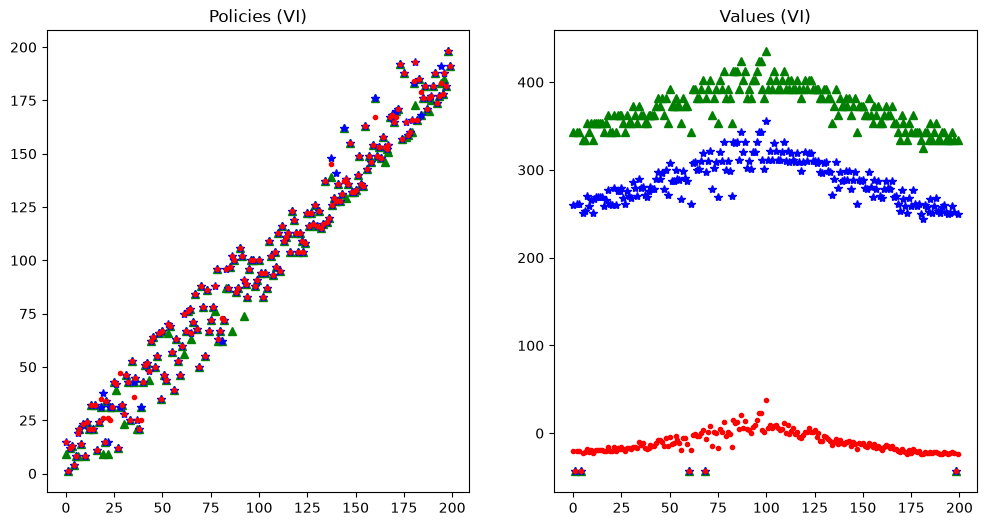

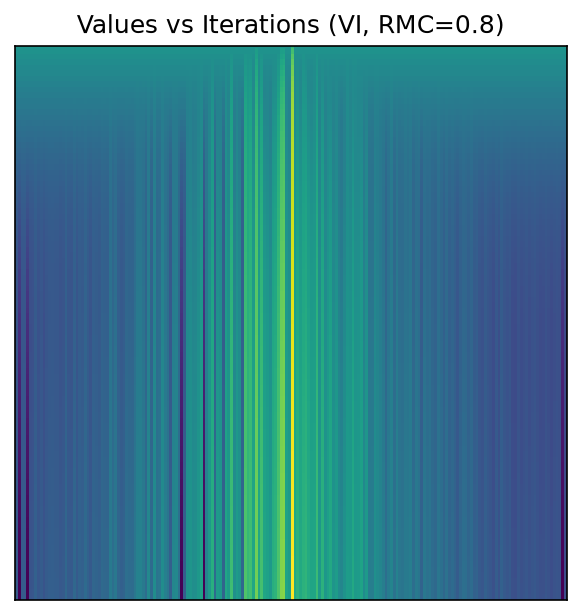

In [12]:
# Results & Plotting Code

# Plot the adjacency matrix we'll be using
world = AdjacencyWorld(
    200, band_size=20, edge_rate=0.1, random_move_chance=0.0, seed=695
)

plt.figure(figsize=(12, 6))
ax1 = plt.subplot(121)
plt.title("Policies (VI)")
ax2 = plt.subplot(122)
plt.title("Values (VI)")

# No randomness in move selection
world.random_move_chance = 0.0
all_values = value_iteration(world, 100)
policy_vi_00 = compute_policy_from_values(world, all_values[-1])
ax1.plot(policy_vi_00, "g^")
ax2.plot(all_values[-1], "g^")

# Some randomness in move selection
world.random_move_chance = 0.2
all_values = value_iteration(world, 100)
policy_vi_02 = compute_policy_from_values(world, all_values[-1])
ax1.plot(policy_vi_02, "b*")
ax2.plot(all_values[-1], "b*")

# A lot of randomness in move selection
world.random_move_chance = 0.8
all_values = value_iteration(world, 100)
policy_vi_08 = compute_policy_from_values(world, all_values[-1])
ax1.plot(policy_vi_08, "r.")
ax2.plot(all_values[-1], "r.")

# Visualize the evolution of the values over time
plot_adjacency_mat(all_values)
plt.title("Values vs Iterations (VI, RMC=0.8)")


print("== Policy 1 ==")
evaluate_policy_multiple(world, policy_1)

print("== Policy 2 ==")
evaluate_policy_multiple(world, policy_2)

print("== Policy Value Iteration (rmc = 0.2) ==")
evaluate_policy_multiple(world, policy_vi_02)

print(policy_vi_02)

None

## P3.3 Policy Iteration

Finally, you will implement policy iteration and compare the results to value iteration. The procedure (see lecture slides) involves iteratively computing the values for the given policy and then re-computing the best policy given the current estimate of the values.

**TASK** Implement "full" Policy Iteration by completing `policy_iteration` below. Note that you already have most of the pieces you need to complete this function! You already know how to use linear algebra to compute the values given a policy *and* you already know how to compute the "best" action (policy) given an estimate of the values. Feel free to use functions you have already implemented in your response.

**CODE** Include your implementation in your writeup.

**PLOTS** Include the generated plots in your writeup.

**QUESTION** (2-4 sentences) Which approach converges more quickly? Why?

In [13]:
# Starter Code


def policy_iteration(world, num_iterations, gamma=0.98):
    values = world.rewards.copy()
    all_values = []
    all_values.append(values.copy())
    # Get random policy
    policy = [
        random.choice(world.get_actions_for_state(state)) for state in world.states
    ]

    for ii in range(num_iterations):
        # Update the values (using solution)
        # raise NotImplementedError()
        values = evaluate_policy(world, policy, gamma)
        old_policy = np.array(policy)

        # Update the policy
        # raise NotImplementedError()
        policy = compute_policy_from_values(world, values)
        all_values.append(values.copy())

        # Terminate (break) if the policy does not change between steps
        # raise NotImplementedError
        if np.array_equal(policy, old_policy):
            break

    return policy, all_values

Value Iteration Time: 0.595146894454956
Policy Iteration Time: 0.049345970153808594
Value Iteration Avg. Value: 155.74897560850138
Policy Iteration Avg. Value: 155.74897560850138


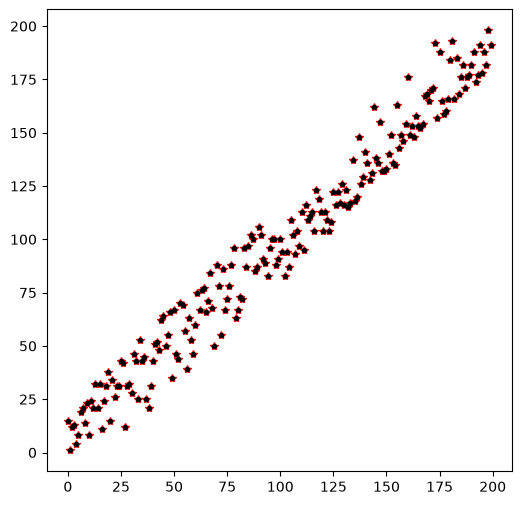

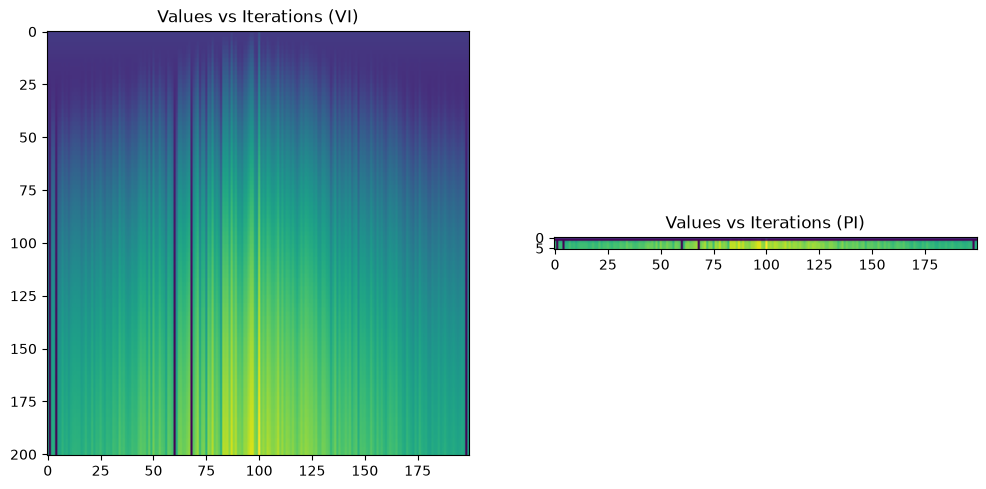

In [14]:
# A lot of randomness in move selection
import time

world = AdjacencyWorld(200, band_size=20, edge_rate=0.1, random_move_chance=0.5)

stime = time.time()
all_values_vi = value_iteration(world, 100)
policy_vi = compute_policy_from_values(world, all_values_vi[-1])
print(f"Value Iteration Time: {time.time() - stime}")

stime = time.time()
policy_pi, all_values_pi = policy_iteration(world, 100)
print(f"Policy Iteration Time: {time.time() - stime}")

plt.figure(figsize=(6, 6))
plt.plot(policy_vi, "r*")
plt.plot(policy_pi, "k.")

plt.figure(figsize=(12, 6))
plt.subplot(121)
plt.imshow(all_values_vi)
plt.title("Values vs Iterations (VI)")
plt.subplot(122)
plt.imshow(all_values_pi)
plt.title("Values vs Iterations (PI)")

pv = evaluate_policy(world, policy_vi)
print(f"Value Iteration Avg. Value: {np.mean(pv)}")
pv = evaluate_policy(world, policy_pi)
print(f"Policy Iteration Avg. Value: {np.mean(pv)}")

None

## P3.4 Bandit Algorithms

Here, you'll be looking in more depth at the Bandit Algorithms we discussed in class. To begin, you are given the same example we saw in the in-class breakout session. You are provided with 10 bandits of an unknown (to the agent) reward distribution. The plot generated in the first plot shows the rewards generated by "pulling" the arms of each bandit.

### P3.4.1 Epsilon Greedy Bandits

I have given you starter code for the epsilon-greedy bandit algorithm we discussed in class.

**TASK** Complete `bandit_epsilon_greedy` and run the evaluation code that follows.

**PLOTS** Include the set of plots (in a single figure) generated by the evaluation code.

**RESULTS** Include in your report the (average) percentage of optimal pulls for each value of epsilon.

**RESULTS** Include in your report the cumulative average reward (the sum of the running-average reward curve) for each value of epsilon.

**QUESTION** (2-4 sentences) For which epsilon is the peak "optimal pull percentage"? Why does the percentage of optimal pulls (and, relatedly the average reward) decrease for the higher values of epsilon?

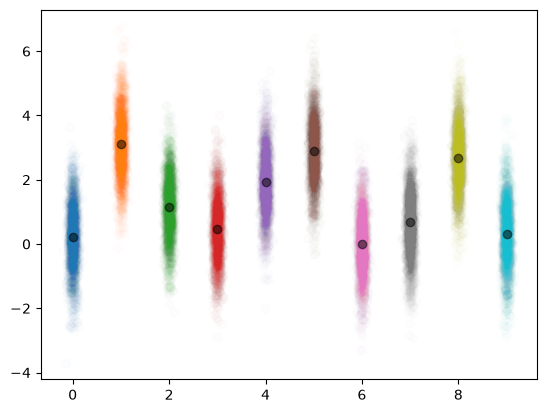

In [15]:
# N-armed bandit
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(695)


# Generate some bandits
class Bandit(object):
    def __init__(self, mean=None, mean_range=[-1, 3], sigma=1.0):
        if mean is None:
            self.mean = random.uniform(min(mean_range), max(mean_range))
        else:
            self.mean = mean
        self.mean_range = mean_range
        self.sigma = sigma

    def pull_arm(self):
        return random.gauss(self.mean, self.sigma)

    def get_data_for_plot(self, width=0.05, num_values=2000):
        xs = np.random.normal(0, width, num_values)
        ys = np.random.normal(self.mean, self.sigma, num_values)
        return xs, ys


def plot_bandits(bandits):
    for ii, bandit in enumerate(bandits):
        xs, ys = bandit.get_data_for_plot()
        plt.scatter(xs + ii, ys, alpha=0.01)
        plt.plot(ii, bandit.mean, "ko", alpha=0.5)


num_bandits = 10
bandits = [Bandit() for _ in range(8)]
bandits.append(Bandit(mean=2.9))
bandits.append(Bandit(mean=3.1))
random.shuffle(bandits)
plot_bandits(bandits)

In [16]:
## Bandit starter code


def bandit_epsilon_greedy(bandits, num_steps=2000, epsilon=0.0, seed=695):
    """
    returns (average reward over time,
             proportion of pulls for each bandit by end)
    """
    random.seed(seed)
    num_pulls_per_bandit = np.zeros(len(bandits))
    tot_reward_per_bandit = np.zeros(len(bandits))
    all_rewards = []  # List of each reward returned per pull.

    for ii in range(num_steps):
        # Pick one of the bandits.
        # raise NotImplementedError()
        if random.random() < epsilon:
            bandit_ind = random.randrange(len(bandits))
        else:
            est = np.divide(tot_reward_per_bandit, num_pulls_per_bandit,
                out=np.zeros(len(bandits)), where=num_pulls_per_bandit > 0)
            bandit_ind = int(np.argmax(est))

        # Data Storage
        reward = bandits[bandit_ind].pull_arm()
        tot_reward_per_bandit[bandit_ind] += reward
        num_pulls_per_bandit[bandit_ind] += 1
        all_rewards.append(reward)

    return (
        np.cumsum(all_rewards) / (np.arange(num_steps) + 1),
        num_pulls_per_bandit / num_steps,
    )

Eps = 0.001 : Optimal Pulls =  78.59% Cumulative Average Reward = 5120.46
Eps = 0.050 : Optimal Pulls =  89.76% Cumulative Average Reward = 5770.64
Eps = 0.100 : Optimal Pulls =  80.70% Cumulative Average Reward = 5616.40
Eps = 0.200 : Optimal Pulls =  73.90% Cumulative Average Reward = 5336.28
Eps = 0.500 : Optimal Pulls =  51.17% Cumulative Average Reward = 4352.01


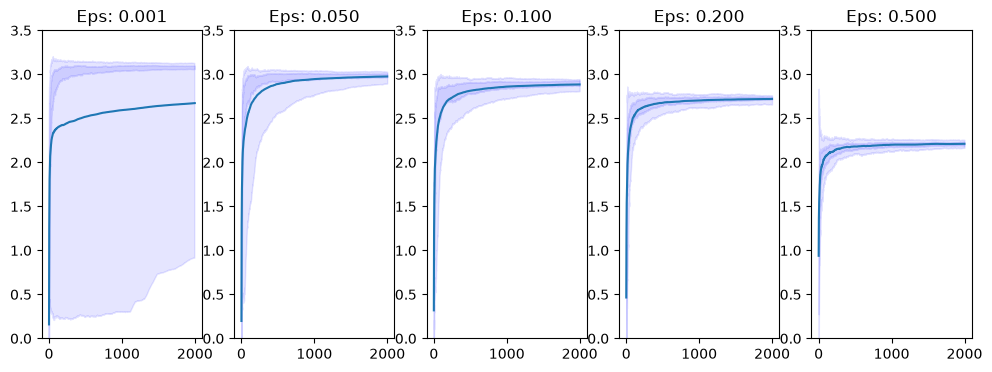

In [17]:
# Plotting Code
plt.figure(figsize=(12, 4))
epsilons = [0.001, 0.05, 0.1, 0.2, 0.5]
best_bandit_ind = bandits.index(max(bandits, key=lambda b: b.mean))
for ii, epsilon in enumerate(epsilons):
    dat = [
        bandit_epsilon_greedy(bandits, epsilon=epsilon, seed=seed)
        for seed in range(100)
    ]
    all_runs, pull_rates = zip(*dat)
    plt.subplot(1, len(epsilons), ii + 1)
    avg_rewards = np.mean(all_runs, axis=0)
    p10_rewards = np.percentile(all_runs, 10, axis=0)
    p30_rewards = np.percentile(all_runs, 30, axis=0)
    p70_rewards = np.percentile(all_runs, 70, axis=0)
    p90_rewards = np.percentile(all_runs, 90, axis=0)
    plt.plot(avg_rewards)
    plt.fill_between(
        range(len(avg_rewards)), p30_rewards, p70_rewards, alpha=0.1, color="blue"
    )
    plt.fill_between(
        range(len(avg_rewards)), p10_rewards, p90_rewards, alpha=0.1, color="blue"
    )
    print(
        f"Eps = {epsilon:0.3f} : Optimal Pulls = "
        f"{100 * np.mean(pull_rates, axis=0)[best_bandit_ind]:6.2f}% "
        f"Cumulative Average Reward = {np.sum(avg_rewards):0.2f}"
    )
    plt.title(f"Eps: {epsilon:0.3f}")
    plt.ylim([0, 3.5])

### P3.4.2 UCB Bandits

**TASK** Implement the UCB Bandit function `bandit_ucb(bandits, num_steps=2000, c=4.0, seed=695)` and run the evaluation code that follows. Your `bandit_ucb` implementation will look a lot like the `bandit_epsilon_greedy`, so you may use that as starter code.

**CODE** Include your implementation of `bandit_ucb` in your writeup.

**PLOTS** Include the set of plots (in a single figure) generated by the evaluation code.

**RESULTS** Include in your report the (average) percentage of optimal pulls for each value of C (the exploration parameter).

**RESULTS** Include in your report the cumulative average reward (the sum of the running-average reward curve) for each value of C.

**TASK** Run the comparison cell at the end of this section, which runs the best epsilon (0.05) and the best C (1.0) for 20,000 steps and plots the *cumulative regret* of each: the expected reward lost, relative to always pulling the best arm.

**PLOTS** Include the regret plot generated by the comparison cell.

**RESULTS** Include the printed regret values at 2,000 and 20,000 steps for each algorithm.

**QUESTION** (3-5 sentences) At 2,000 steps, the best epsilon and the best C have similar optimal-pull percentages. (a) What is the highest optimal-pull percentage epsilon-greedy can *ever* reach with epsilon = 0.05 and 10 arms, and why? (b) Describe how each regret curve grows with time. Why does epsilon-greedy's keep growing while UCB's levels off?

**QUESTION** (2-5 sentences) Why is the average performance of the algorithm poor for very low values of C? What will happen to the performance as the number of trials approach infinity?

**QUESTION** (2-5 sentences) Why is the average performance of the algorithm poor for very high values of C? What will happen to the performance as the number of trials approach infinity?

In [22]:
def bandit_ucb(bandits, num_steps=2000, c=4.0, seed=695):
    """
    returns (average reward over time,
             proportion of pulls for each bandit by end)
    """
    random.seed(seed)
    num_pulls_per_bandit = np.zeros(len(bandits))
    tot_reward_per_bandit = np.zeros(len(bandits))
    all_rewards = []  # List of each reward returned per pull.

    for ii in range(num_steps):
        t = ii + 1  # step count starting at 1, so ln(t) is never ln(0)

        # Pick one of the bandits.
        if np.any(num_pulls_per_bandit == 0):
            bandit_ind = int(np.argmin(num_pulls_per_bandit))
        else:
            est = tot_reward_per_bandit / num_pulls_per_bandit
            bonus = c * np.sqrt(np.log(t) / num_pulls_per_bandit)
            bandit_ind = int(np.argmax(est + bonus))

        # Data Storage
        reward = bandits[bandit_ind].pull_arm()
        tot_reward_per_bandit[bandit_ind] += reward
        num_pulls_per_bandit[bandit_ind] += 1
        all_rewards.append(reward)

    return (
        np.cumsum(all_rewards) / (np.arange(num_steps) + 1),
        num_pulls_per_bandit / num_steps,
    )


c = 0.00100 : Optimal Pulls =  65.47% Cumulative Average Reward = 5897.96
c = 0.01000 : Optimal Pulls =  67.62% Cumulative Average Reward = 5916.56
c = 0.10000 : Optimal Pulls =  71.21% Cumulative Average Reward = 5950.74
c = 0.30000 : Optimal Pulls =  77.18% Cumulative Average Reward = 5967.05
c = 1.00000 : Optimal Pulls =  90.87% Cumulative Average Reward = 5976.94
c = 3.00000 : Optimal Pulls =  67.91% Cumulative Average Reward = 5556.90
c = 10.00000 : Optimal Pulls =  33.68% Cumulative Average Reward = 4392.63


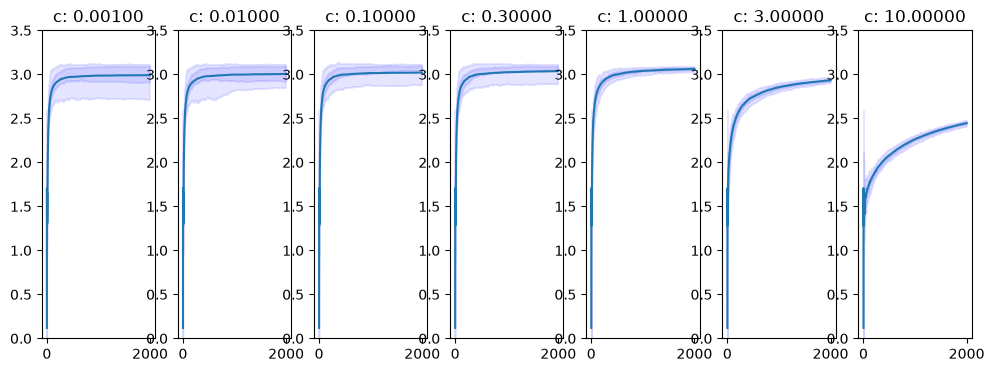

In [23]:

# Plotting Code
plt.figure(figsize=(12, 4))
cs = [1e-3, 1e-2, 1e-1, 3e-1, 1e0, 3e0, 1e1]
best_bandit_ind = bandits.index(max(bandits, key=lambda b: b.mean))
for ii, c in enumerate(cs):
    dat = [bandit_ucb(bandits, c=c, seed=seed) for seed in range(100)]
    all_runs, pull_rates = zip(*dat)
    plt.subplot(1, len(cs), ii + 1)
    avg_rewards = np.mean(all_runs, axis=0)
    p10_rewards = np.percentile(all_runs, 10, axis=0)
    p30_rewards = np.percentile(all_runs, 30, axis=0)
    p70_rewards = np.percentile(all_runs, 70, axis=0)
    p90_rewards = np.percentile(all_runs, 90, axis=0)
    plt.plot(avg_rewards)
    plt.fill_between(
        range(len(avg_rewards)), p30_rewards, p70_rewards, alpha=0.1, color="blue"
    )
    plt.fill_between(
        range(len(avg_rewards)), p10_rewards, p90_rewards, alpha=0.1, color="blue"
    )
    print(
        f"c = {c:0.5f} : Optimal Pulls = "
        f"{100 * np.mean(pull_rates, axis=0)[best_bandit_ind]:6.2f}% "
        f"Cumulative Average Reward = {np.sum(avg_rewards):0.2f}"
    )
    plt.title(f"c: {c:0.5f}")
    plt.ylim([0, 3.5])

eps-greedy (eps=0.05): regret at 2k = 223, at 20k = 1791
UCB (c=1.0): regret at 2k = 74, at 20k = 98


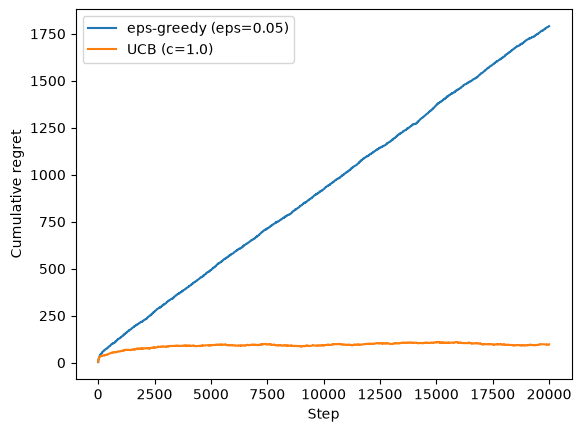

In [24]:
# Comparison: best epsilon vs best C over a longer horizon
T = 20000
mu_star = max(b.mean for b in bandits)
steps = np.arange(1, T + 1)
plt.figure()
for label, fn, kw in [
    ("eps-greedy (eps=0.05)", bandit_epsilon_greedy, dict(epsilon=0.05)),
    ("UCB (c=1.0)", bandit_ucb, dict(c=1.0)),
]:
    runs = [fn(bandits, num_steps=T, seed=seed, **kw)[0] for seed in range(50)]
    regret = (steps * (mu_star - np.array(runs))).mean(axis=0)
    plt.plot(steps, regret, label=label)
    print(f"{label}: regret at 2k = {regret[1999]:.0f}, at 20k = {regret[-1]:.0f}")
plt.xlabel("Step")
plt.ylabel("Cumulative regret")
plt.legend()
None